In [ ]:
import ee
import geemap

# =====================================================================
# STEP 1: INITIALIZE USING YOUR SECURED CLOUD PROJECT ID
# =====================================================================
print("Initializing Earth Engine Client Pipeline...")

# 1. Authorize your browser environment user credentials
ee.Authenticate()

# 2. Bind the runtime pipeline directly to your newly created cloud container
ee.Initialize(project='decisive-scion-507218-s4')

print("Success! Connection established. Processing geospatial datasets...")


# =====================================================================
# STEP 2: DEFINE STUDY AREA (Kolkata Bounding Box Grid)
# =====================================================================
# Format: Rectangle([min_lon, min_lat, max_lon, max_lat])
kolkata_aoi = ee.Geometry.Rectangle([88.20, 22.45, 88.45, 22.65])


# =====================================================================
# STEP 3: LANDSAT 8 DATA COLLECTION (For Heat/LST Layer)
# =====================================================================
def mask_landsat_clouds(image):
    qa = image.select('QA_PIXEL')
    cloud_shadow_bit = (1 << 4)
    cloud_bit = (1 << 3)

    # Using functional Earth Engine .And() syntax
    mask = (qa.bitwiseAnd(cloud_shadow_bit).eq(0)
            .And(qa.bitwiseAnd(cloud_bit).eq(0)))
    return image.updateMask(mask)

# Filter Landsat 8 Surface Reflectance for Summer Months (Peak Heat)
landsat_composite = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
                     .filterBounds(kolkata_aoi)
                     .filterDate('2023-04-01', '2023-06-30')
                     .map(mask_landsat_clouds)
                     .median()  # Generates cloud-free median mosaic pixels
                     .clip(kolkata_aoi))

# Select Optical Bands and Thermal Surface Temperature (ST_B10)
landsat_final = landsat_composite.select(['SR_B4', 'SR_B3', 'SR_B2', 'ST_B10'])


# =====================================================================
# STEP 4: SENTINEL-2 DATA COLLECTION (For Flood Layer)
# =====================================================================
def mask_sentinel_clouds(image):
    qa = image.select('QA60')
    cloud_bit = (1 << 10)
    cirrus_bit = (1 << 11)

    # Using functional Earth Engine .And() syntax
    mask = (qa.bitwiseAnd(cloud_bit).eq(0)
            .And(qa.bitwiseAnd(cirrus_bit).eq(0)))
    return image.updateMask(mask)

# Filter Harmonized Sentinel-2 Surface Reflectance for Monsoon Months
sentinel_composite = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                      .filterBounds(kolkata_aoi)
                      .filterDate('2023-07-01', '2023-09-30')
                      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                      .map(mask_sentinel_clouds)
                      .median()
                      .clip(kolkata_aoi))

# Select standard 10-meter spatial resolution bands
sentinel_final = sentinel_composite.select(['B4', 'B3', 'B2', 'B8'])


# =====================================================================
# STEP 5: SUBMIT EXPORT TASKS DIRECTLY TO GOOGLE DRIVE
# =====================================================================
print("Initiating cloud export tasks to your Google Drive...")

# Export Landsat 8 Asset (Native 30m Grid)
task_landsat = ee.batch.Export.image.toDrive(
    image=landsat_final,
    description='Kolkata_Landsat_Heat_Layer',
    scale=30,
    region=kolkata_aoi,
    fileFormat='GeoTIFF'
)
task_landsat.start()

# Export Sentinel-2 Asset (Native 10m Grid)
task_sentinel = ee.batch.Export.image.toDrive(
    image=sentinel_final,
    description='Kolkata_Sentinel_Flood_Layer',
    scale=10,
    region=kolkata_aoi,
    fileFormat='GeoTIFF'
)
task_sentinel.start()

print("\n🎉 Success! Tasks have been successfully dispatched to your account.")
print("Open your Google Drive or use your Earth Engine Task Tracker to monitor progress.")


Initializing Earth Engine Client Pipeline...
Success! Connection established. Processing geospatial datasets...
Initiating cloud export tasks to your Google Drive...

🎉 Success! Tasks have been successfully dispatched to your account.
Open your Google Drive or use your Earth Engine Task Tracker to monitor progress.


Mounting Google Drive...
Mounted at /content/drive
Reading Landsat Thermal Data...


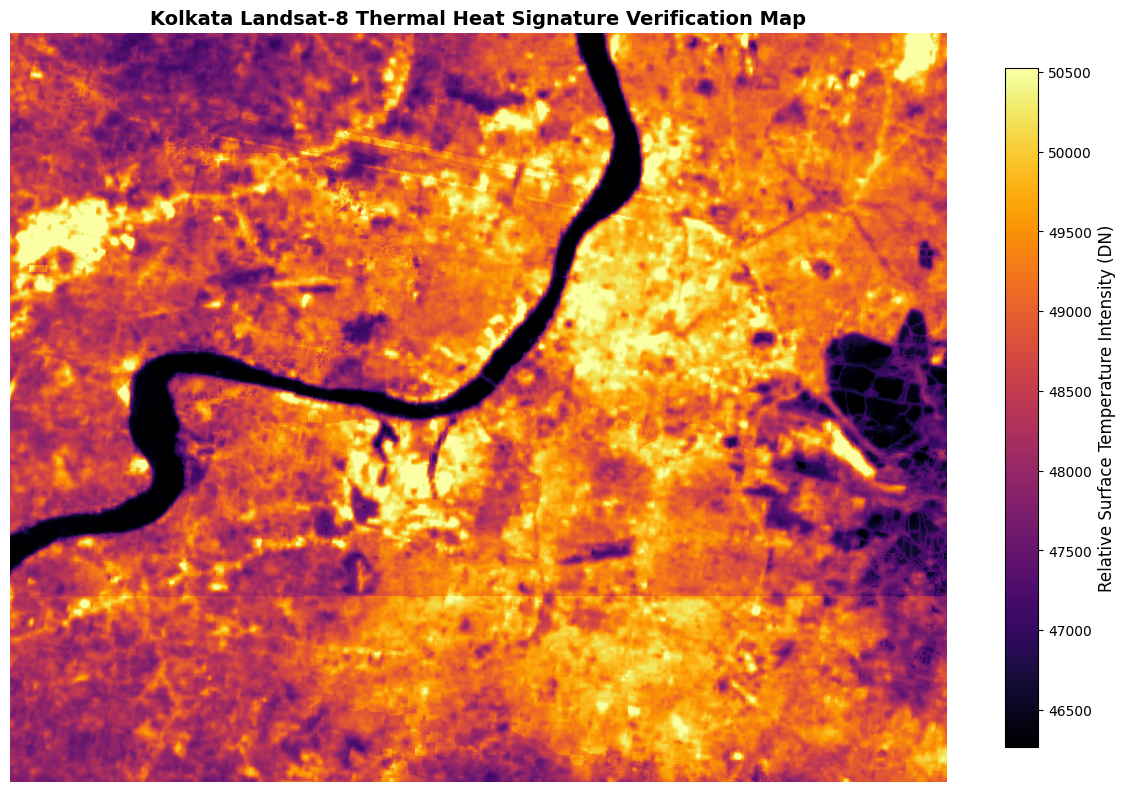

Success! Your heat map has been generated and verified.


In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# 1. Mount your Google Drive securely to access the files
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

# 2. Define the exact path to your Landsat Heat Layer inside your Drive
# (Google Colab paths always start with '/content/drive/My Drive/')
landsat_path = '/content/drive/My Drive/Kolkata_Landsat_Heat_Layer.tif'

print("Reading Landsat Thermal Data...")
try:
    with rasterio.open(landsat_path) as src:
        # In our extraction script, Landsat exported bands are:
        # Band 1: SR_B4 (Red), Band 2: SR_B3 (Green), Band 3: SR_B2 (Blue), Band 4: ST_B10 (Thermal)
        # We select Band 4 directly for the thermal heat signature
        thermal_band = src.read(4)

        # Convert to float for mathematical manipulation
        thermal_data = thermal_band.astype(float)

        # 3. Handle background/null pixels (fill values usually export as 0)
        # We mask them out so they don't skew our heat map visualization scale
        thermal_masked = np.where(thermal_data == 0, np.nan, thermal_data)

        # 4. Apply a contrast stretch based on regional surface temperatures (2nd to 98th percentile)
        p_low = np.nanpercentile(thermal_masked, 2)
        p_high = np.nanpercentile(thermal_masked, 98)

        # 5. Render the Kolkata Thermal Map Layout
        plt.figure(figsize=(12, 10))

        # 'inferno' or 'magma' are ideal colormaps for representing heat signatures
        img = plt.imshow(thermal_masked, cmap='inferno', vmin=p_low, vmax=p_high)

        # Add layout accessories (Colorbar indicator scale, Title)
        cbar = plt.colorbar(img, orientation='vertical', shrink=0.7)
        cbar.set_label('Relative Surface Temperature Intensity (DN)', fontsize=12)

        plt.title("Kolkata Landsat-8 Thermal Heat Signature Verification Map", fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print("Success! Your heat map has been generated and verified.")

except Exception as e:
    print(f"\n❌ Error loading the image file!")
    print(f"Please check your Google Drive and confirm that 'Kolkata_Landsat_Heat_Layer.tif' is fully saved there.")
    print(f"Error Details: {e}")


In [ ]:
import ee
import pandas as pd

# Fetch the live background tasks from your active project
tasks = ee.batch.Task.list()

# Format the results into a clean table
task_list = []
for t in tasks:
    task_list.append({
        'Layer Name': t.config.get('description'),
        'Current State': t.state,
        'Task ID': t.id
    })

df = pd.DataFrame(task_list)
df.head()


,Layer Name,Current State,Task ID
0,Kolkata_Sentinel_Flood_Layer,FAILED,6PDSJS63MOJVQ2VV2AZMW56I
1,Kolkata_Landsat_Heat_Layer,COMPLETED,ME2AHS4HJLFVGJ4M3WTZNVW4


In [ ]:
import ee

# 1. Fetch the live task objects directly from the API
all_tasks = ee.batch.Task.list()

print("--- Earth Engine Cloud Diagnostic Report ---")
for t in all_tasks:
    # Isolate the failed Sentinel layer task
    if t.config.get('description') == 'Kolkata_Sentinel_Flood_Layer':
        status = t.status()
        print(f"Layer Name:    {status.get('description')}")
        print(f"Current State: {status.get('state')}")
        print(f"Error Message: {status.get('error_message')}")
        break


--- Earth Engine Cloud Diagnostic Report ---
Layer Name:    Kolkata_Sentinel_Flood_Layer
Current State: FAILED
Error Message: Image.select: Band pattern 'B4' was applied to an Image with no bands. See https://developers.google.com/earth-engine/guides/debugging#no-bands


In [ ]:
import ee

# 1. Define your study area boundary coordinate box
kolkata_aoi = ee.Geometry.Rectangle([88.20, 22.45, 88.45, 22.65])

# 2. Pixel-level bitmask function to clear clouds dynamically
def mask_sentinel_clouds(image):
    qa = image.select('QA60')
    cloud_bit = (1 << 10)
    cirrus_bit = (1 << 11)
    mask = (qa.bitwiseAnd(cloud_bit).eq(0)
            .And(qa.bitwiseAnd(cirrus_bit).eq(0)))
    return image.updateMask(mask)

# 3. FIXED: Completely removed the strict 20% cloud metadata filter line
sentinel_composite_fixed = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                            .filterBounds(kolkata_aoi)
                            .filterDate('2023-07-01', '2023-09-30') # Target Monsoon timeline
                            .map(mask_sentinel_clouds) # Mask cloudy pixels out of EVERY image
                            .median() # Stitches together the cloud-free remnants
                            .clip(kolkata_aoi))

# 4. Select standard 10-meter spatial resolution bands (Red, Green, Blue, NIR)
sentinel_final_fixed = sentinel_composite_fixed.select(['B4', 'B3', 'B2', 'B8'])

# 5. Re-submit the background export task with safety parameters enabled
print("Submitting the cloud-resilient monsoon data extraction task...")
task_sentinel_fixed = ee.batch.Export.image.toDrive(
    image=sentinel_final_fixed,
    description='Kolkata_Sentinel_Flood_Layer',
    scale=10,
    region=kolkata_aoi,
    fileFormat='GeoTIFF',
    maxPixels=1e13
)
task_sentinel_fixed.start()

print("\n🎉 Success! A brand new, robust Sentinel-2 cloud task has been dispatched.")
print("Run your task tracker cell in a minute to confirm it reads 'READY' or 'RUNNING'.")


Submitting the cloud-resilient monsoon data extraction task...

🎉 Success! A brand new, robust Sentinel-2 cloud task has been dispatched.
Run your task tracker cell in a minute to confirm it reads 'READY' or 'RUNNING'.


In [ ]:
import ee
import pandas as pd

# Fetch and display the active background task logs
tasks = ee.batch.Task.list()
task_df = pd.DataFrame([{
    'Layer Name': t.config.get('description'),
    'Current State': t.state,
    'Task ID': t.id
} for t in tasks[:3]])

task_df


,Layer Name,Current State,Task ID
0,Kolkata_Sentinel_Flood_Layer,READY,GZ6EHXYS5ZZLSVAOU3HWIYGU
1,Kolkata_Sentinel_Flood_Layer,FAILED,6PDSJS63MOJVQ2VV2AZMW56I
2,Kolkata_Landsat_Heat_Layer,COMPLETED,ME2AHS4HJLFVGJ4M3WTZNVW4


Mounting Google Drive...
Mounted at /content/drive
Reading Sentinel-2 Multi-Spectral Data...


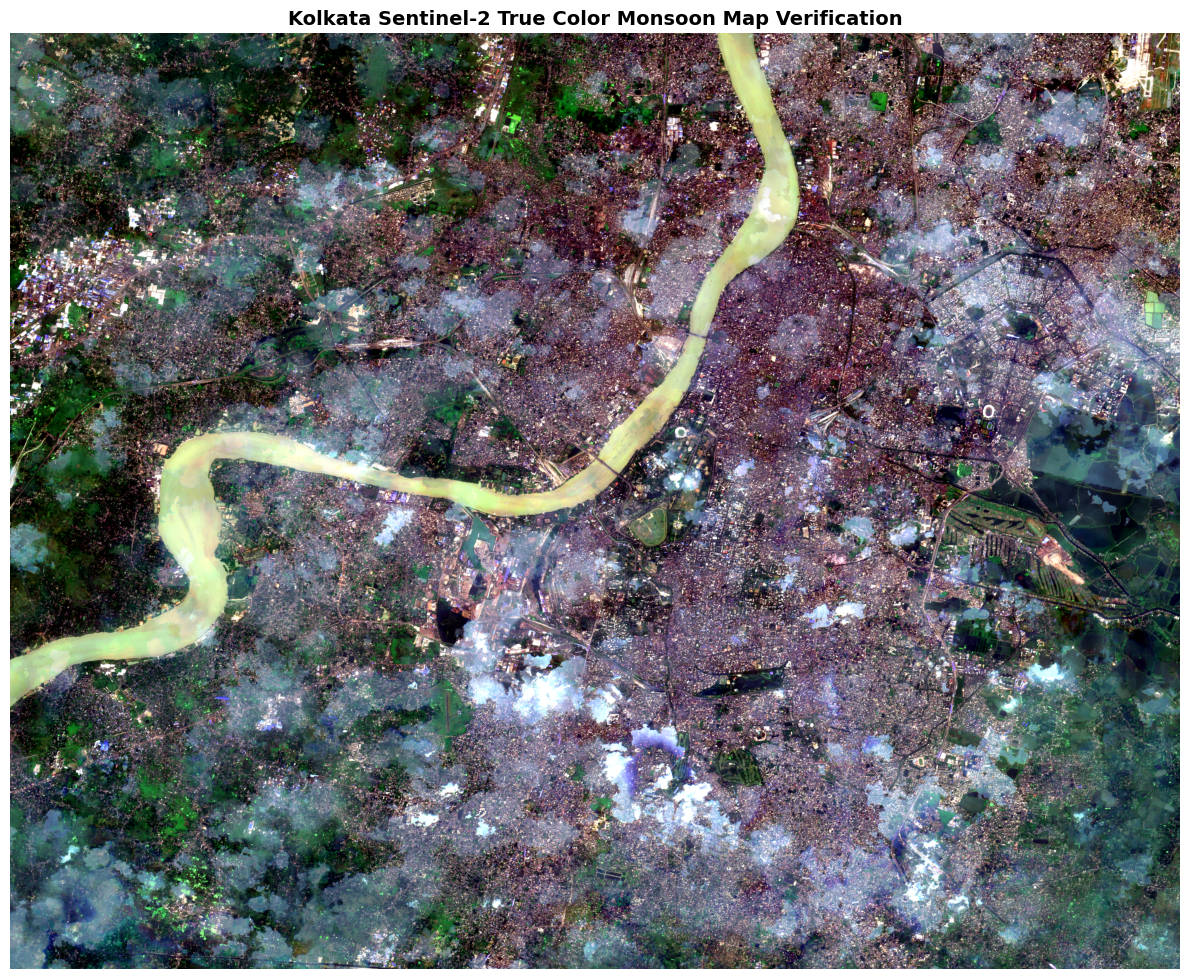

Success! Your Sentinel-2 flood basemap mosaic has been generated and verified.


In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# 1. Mount your Google Drive securely to access the files
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

# 2. Define the exact path to your Sentinel Flood Layer inside your Drive
sentinel_path = '/content/drive/My Drive/Kolkata_Sentinel_Flood_Layer.tif'

print("Reading Sentinel-2 Multi-Spectral Data...")
try:
    with rasterio.open(sentinel_path) as src:
        # In our extraction script, Sentinel-2 exported bands are:
        # Band 1: B4 (Red), Band 2: B3 (Green), Band 3: B2 (Blue), Band 4: B8 (Near-Infrared)
        # We read the first three bands to reconstruct a True Color (RGB) image matrix
        red = src.read(1).astype(float)
        green = src.read(2).astype(float)
        blue = src.read(3).astype(float)

        # 3. Handle background mask pixels (where value is 0)
        # We replace zero values with NaN so they do not skew our contrast balance scaling
        red[red == 0] = np.nan
        green[green == 0] = np.nan
        blue[blue == 0] = np.nan

        # Stack individual 2D arrays into a single 3D image matrix (Height, Width, 3 Bands)
        rgb_raw = np.dstack((red, green, blue))

        # 4. CONTRAST STRETCH: Squeeze the values between the 2nd and 98th percentile
        # This completely avoids the "white wash" effect by ignoring extreme outlier pixels
        rgb_stretched = np.zeros_like(rgb_raw)
        for band_idx in range(3):
            band_data = rgb_raw[:, :, band_idx]
            p_low = np.nanpercentile(band_data, 2)
            p_high = np.nanpercentile(band_data, 98)

            # Map values linearly between 0.0 (darkest) and 1.0 (brightest)
            rgb_stretched[:, :, band_idx] = np.clip((band_data - p_low) / (p_high - p_low), 0, 1)

        # Replace any leftover NaNs (the empty background) with clean black pixels for display
        rgb_stretched = np.nan_to_num(rgb_stretched, nan=0.0)

        # 5. Render the Kolkata True Color Map Layout
        plt.figure(figsize=(12, 10))
        plt.imshow(rgb_stretched)

        plt.title("Kolkata Sentinel-2 True Color Monsoon Map Verification", fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print("Success! Your Sentinel-2 flood basemap mosaic has been generated and verified.")

except Exception as e:
    print(f"\n❌ Error loading the image file!")
    print(f"Please check your Google Drive and confirm that 'Kolkata_Sentinel_Flood_Layer.tif' has fully completed saving.")
    print(f"Error Details: {e}")
